# Prova 2 - Fit e diagnostica

Analizzare un dataset già acquisito mediante un fit pesato. Stimare i parametri identificabili, ricavarne incertezze e correlazioni e valutare il modello con residui, pull, chi quadrato e p-value.

In [49]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit
from scipy.stats import chi2
from scipy.signal import find_peaks

ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ARANCIONE = "#DD8039"
plt.rcParams.update(
    {
        "figure.figsize": (8.2, 4.6),
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "font.size": 11,
        "legend.frameon": False,
    }
)

## Attività 1: Caricamento e controllo dei dati

1. Caricare il file senza modificare l’ordine delle righe.
2. Verificare che gli array abbiano la stessa lunghezza, contengano valori finiti, abbiano incertezze positive e posizioni ordinate.
3. Stampare numero di punti, intervallo di x e intervalli di y e sigma_y.
4. Rappresentare i dati con barre di errore, senza fit.
5. Dal grafico stimate il fondo, il massimo centrale, la distanza tra due frange e la posizione del primo minimo dell’inviluppo, se visibile.

In [50]:
dati = np.genfromtxt("dati_fit_interferenza.csv", delimiter=",", names=True)    #Carica il file CSV assegnando i nomi delle colonne dalle intestazioni
x = dati["x"]
y = dati["y"]
sigma_y = dati["sigma_y"]

print("Stessa lunghezza?", len(x) == len(y) and len(sigma_y) == len(x)) #Verifiche di correttezza sugli array
print("Valori finiti?", np.all(np.isfinite(x)) and np.all(np.isfinite(y)) and np.all(np.isfinite(sigma_y)))
print("Incertezze positive?", sigma_y.all()>0)
print("Posizioni ordinate?", np.all(x[:-1] < x[1:]), "\n")

print("Numero di punti: ", len(x))  #Stampa delle informazioni descrittive del dataset
print("Intervallo di x: ", x.min(), " < x < ", x.max())
print("Intervallo di y: ", y.min(), " < y < ", y.max())
print("Intervallo di sigma_y: ", sigma_y.min(), " < sigma_y < ", sigma_y.max())

Stessa lunghezza? True
Valori finiti? True
Incertezze positive? True
Posizioni ordinate? True 

Numero di punti:  201
Intervallo di x:  -5.0  < x <  5.0
Intervallo di y:  49.709  < y <  549.58
Intervallo di sigma_y:  0.1576531  < sigma_y <  0.5242042


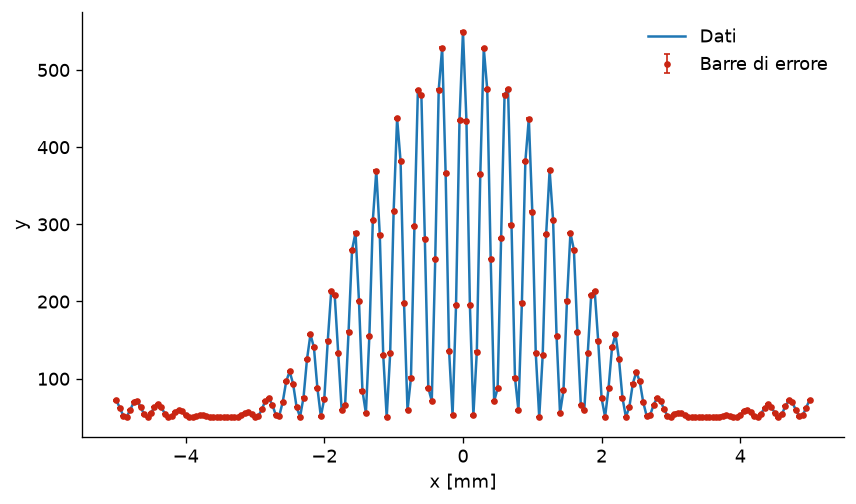

In [51]:
fig, ax = plt.subplots()
ax.plot(x, y, label="Dati")
ax.set(xlabel = "x [mm]" , ylabel = "y")
ax.errorbar(    #Visualizza i dati sperimentali con le relative barre d'errore
    x,
    y,
    yerr=sigma_y,
    fmt=".",
    color=ROSSO,
    ecolor=ROSSO,
    label="Barre di errore",
    markersize=6,
    capsize=2,
    linewidth=1.0,
)
ax.legend()
plt.show()

## Attività 2: Stime iniziali e bounds

In [52]:
#stima del fondo B_0
y_esterni = y[abs(x) > 2.5]
B_0 = np.median(y_esterni)  #fondo

#stima del picco massimo centrale I0_0
I0_0 = y.max() - B_0    #picco

#stima di alpha
regione_destra = (x > 0.2) & (x < 1.5)     #Seleziona la regione a destra del picco centrale (escludendo il centro esatto per evitare di prendere il picco massimo)
x_destra = x[regione_destra]
y_destra = y[regione_destra]

indice_minimo = np.argmin(y_destra)        #Trova la posizione x del punto con l'intensità y più bassa in questa zona (argmin ritorna l'indice)
x_min = x_destra[indice_minimo]            #Prende la x tra quelle selezionate che ha l'intensità y più bassa

alpha_0 = np.pi / x_min                      #Calcola la stima iniziale di alpha

#stima di delta
indici_picchi, _ = find_peaks(y, distance=5, prominence=10) #Trova gli indici dei picchi nei dati
x_picchi = x[indici_picchi]                                 #Estrae le posizioni x corrispondenti ai picchi
dx = np.mean(np.diff(x_picchi))                             #Calcola le distanze tra picchi consecutivi (diff) e poi la media
delta_0 = np.pi / dx                                          #Calcola la stima iniziale di delta


#definisco i bounds rispettivamente su B_0, I0_0, alpha, delta
lower = [0.0, 0.0, 0.10, 1.0]           
upper = [np.inf, np.inf, 3.0, 12.0]

print("B_0: ")
print("B_0 = ", B_0)
print("Bounds: ", lower[0], " < B_0 < ", upper[0])
print("Criterio di scelta: stimato con la mediana dei valori esterni \n")

print("I0_0: ")
print("I0_0 = ", I0_0)
print("Bounds: ", lower[1], " < I0_0 < ", upper[1])
print("Criterio di scelta: ottenuto come la differenza tra il massimo y_max e il fondo B_0 \n")

print("alpha: ")
print("alpha_0 = ", alpha_0)
print("Bounds: ", lower[2], " < alpha_0 < ", upper[2])        #alpha pericolosamente vicino al bound superiore, però curve_fit lo ritocca verso il basso
print("Criterio di scelta: stimato con pi/x_min \n")

print("delta: ")
print("delta_0 = ", delta_0)
print("Bounds: ", lower[3], " < delta_0 < ", upper[3])
print("Criterio di scelta: stimato con pi/dx")

B_0: 
B_0 =  53.162499999999994
Bounds:  0.0  < B_0 <  inf
Criterio di scelta: stimato con la mediana dei valori esterni 

I0_0: 
I0_0 =  496.4175
Bounds:  0.0  < I0_0 <  inf
Criterio di scelta: ottenuto come la differenza tra il massimo y_max e il fondo B_0 

alpha: 
alpha_0 =  2.855993321445266
Bounds:  0.1  < alpha_0 <  3.0
Criterio di scelta: stimato con pi/x_min 

delta: 
delta_0 =  7.352663657337812
Bounds:  1.0  < delta_0 <  12.0
Criterio di scelta: stimato con pi/dx


## Attività 3: Fit pesato

In [53]:
def modello(x, B_0, I0_0, alpha_0, delta_0,):
    E = np.sinc(alpha_0 * x / np.pi) ** 2
    C = np.cos(delta_0 * x) ** 2
    return B_0 + I0_0 * E * C

p0 = np.array([B_0, I0_0, alpha_0, delta_0])    #lista dei parametri

### curve_fit
curve_fit (proveniente dal modulo scipy.optimize) è uno strumento statistico e numerico che implementa il metodo dei minimi quadrati non lineari (di solito tramite l'algoritmo di Levenberg-Marquardt).Il suo scopo è trovare l'insieme dei parametri della funzione teorica (modello) che minimizzano la somma dei quadrati dei residui pesati tra i dati sperimentali y e la curva teorica calcolata.

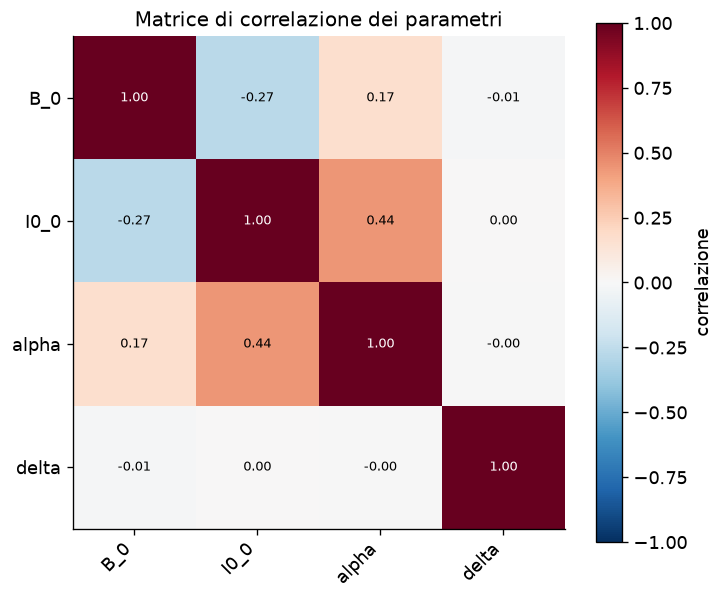

In [54]:
popt, pcov = curve_fit( #restituisce popt array che contiene i valori ottimali dei parametri e pcov matrice di covarianza dei parametri (incertezze sulla diagonale e correlazioni fuori dalla diagonale)
modello, x, y,          #modello funzione che definisce l'equazione fisica del fenomeno, x e y dati sperimentali (rispettivamente posizione e intensità misurata)
p0=p0,                  #vettore dei parametri iniziali da cui inizia l'ottimizzazione. fornire dei valori di partenza fisicamente sensati è fondamentale per aiutare l'algoritmo a orientarsi e convergere rapidamente verso il minimo globale
sigma=sigma_y,          #incertezze verticali (gli errori associati a ciascuna misura di y, calcolati tramite la statistica di Poisson)
absolute_sigma=True,    #indica che le incertezze passate in sigma sono assolute e non relative. garantisce che la matrice di covarianza e i relativi errori sui parametri vengano scalati correttamente in base alle incertezze reali dei dati
bounds=(lower, upper),  #vincoli fisici (limiti inferiori e superiori) per ciascun parametro, impediscono all'algoritmo di esplorare regioni dello spazio dei parametri prive di senso fisico (ad esempio valori negativi dove non previsti)
maxfev=100000           #numero massimo di valutazioni (iterazioni) che la funzione esegue prima di interrompersi
)

parametri = ['B_0', 'I0_0', 'alpha', 'delta']   #lista contenente i nomi dei parametri ottimizzati per le etichette del grafico

error = np.sqrt(np.diagonal(pcov)) #Calcola le deviazioni standard dai vettori diagonali di pcov

corr_matrix = pcov / np.outer(error, error) #Calcola la matrice di correlazione normalizzando la matrice di covarianza

fig, ax = plt.subplots(figsize=(6.2, 5.2))
image = ax.imshow(corr_matrix, vmin=-1, vmax=1, cmap="RdBu_r")  #Visualizza la matrice di correlazione come una mappa di calore (heatmap); vmin e vmax fissano la scala dei colori tra -1 e 1; cmap imposta la mappa di colori (dal blu al rosso)
ax.set_xticks(range(len(parametri)), parametri, rotation=45, ha="right")    #Configura le tacche e le etichette sull'asse X
ax.set_yticks(range(len(parametri)), parametri)    #Configura le tacche e le etichette sull'asse X
ax.set_title("Matrice di correlazione dei parametri")

for row in range(len(parametri)):   #Ciclo sui coefficienti della matrice per inserire i valori numerici all'interno delle celle
    for column in range(len(parametri)):
        color = "white" if abs(corr_matrix[row, column]) > 0.55 else "black"    #Sceglie il colore del testo (bianco se il valore assoluto della correlazione > 0.55 per leggibilità, altrimenti nero)
        ax.text(column, row, f"{corr_matrix[row, column]:.2f}",       #Scrive il valore numerico della correlazione arrotondato a due cifre decimali al centro della cella
                ha="center", va="center", fontsize=8, color=color)

fig.colorbar(image, ax=ax, label="correlazione")    #Aggiunge la barra laterale dei colori (colorbar) per indicare la scala di correlazione
plt.tight_layout()      #Ottimizza la spaziatura degli elementi nella figura per evitare sovrapposizioni
plt.show()

## Attività 4: Diagnostica del fit

In [55]:
print(*popt)    #scompatta e stampa i valori ottimali dei quattro parametri del modello (B_0, I0_0, alpha, delta) trovati dal curve_fit

y_fit = modello(x, *popt)   #genera la curva teorica valutando il modello con i parametri appena ottimizzati

r = y - y_fit                   #residui
rho = r / sigma_y               #pull (residui normlizzati)
chi2_obs = np.sum(rho**2)       #chi quadro
v = len(y) - 4                  #dof
chi2_rid = chi2_obs/v           #chi quadro ridotto
p_value = chi2.sf(chi2_obs, v)  #p_value

print("chi2 ridotto: ", chi2_rid)
print("p_value: ", p_value)

49.98932280960327 500.00023955988945 0.8999460241003617 10.000057731009045
chi2 ridotto:  1.135003898853046
p_value:  0.09389330762279363


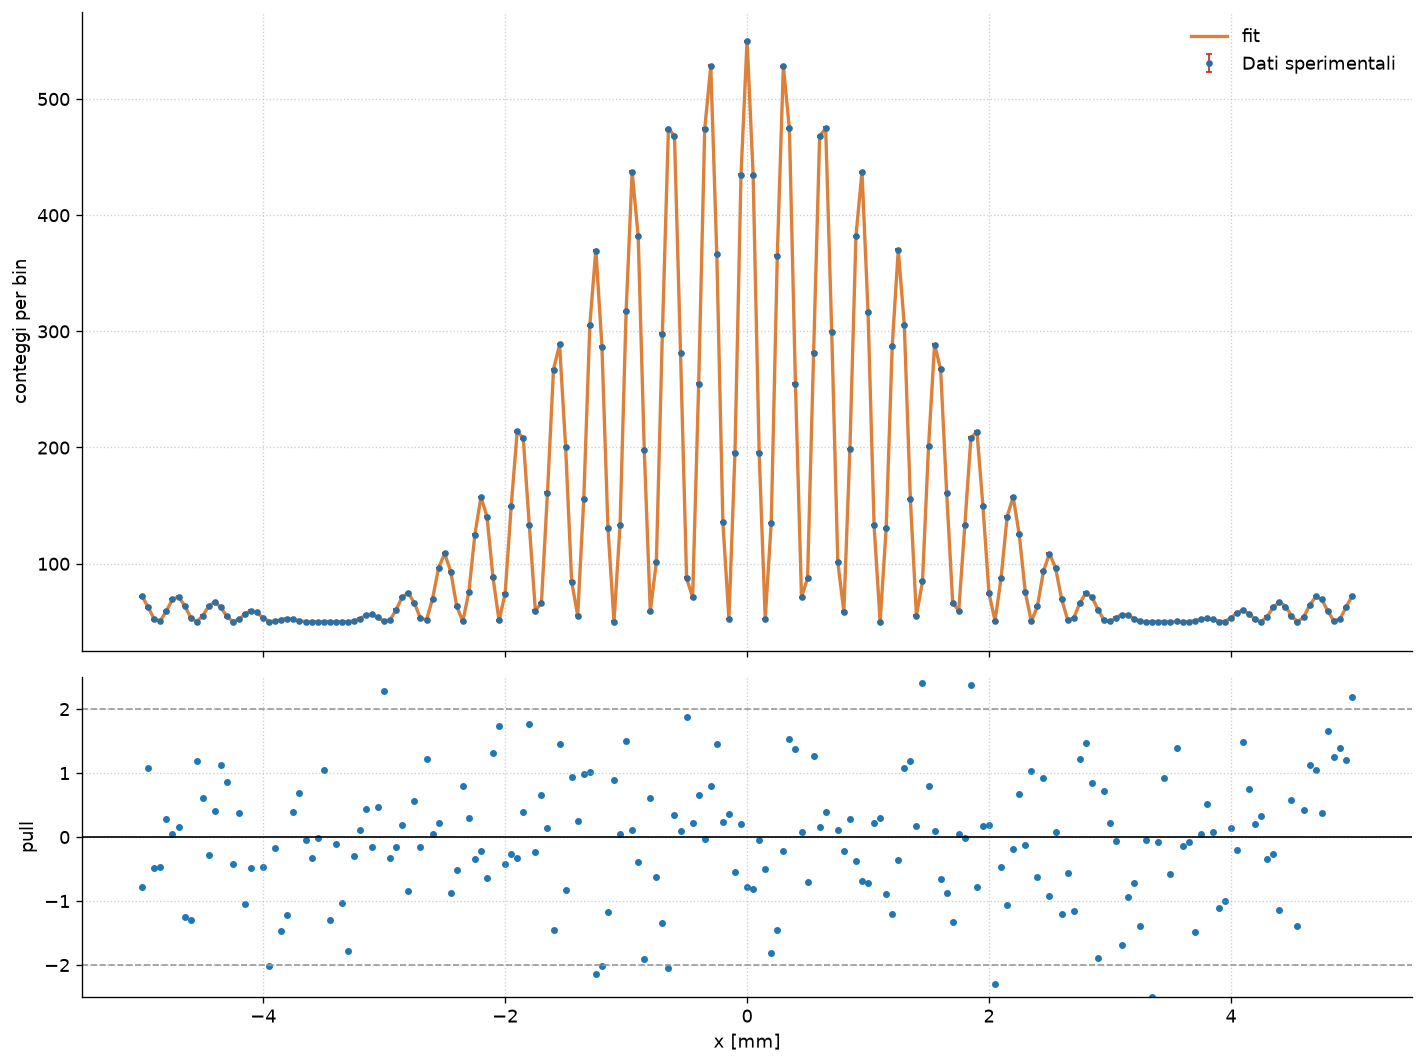

In [56]:
fig, (ax_top, ax_bottom) = plt.subplots(    #Inizializza la figura con due subplots sovrapposti (3:1 come proporzione di altezza)
    2, 1, figsize=(12, 9), sharex=True,
    gridspec_kw={"height_ratios": [2, 1]},
)

#Grafico superiore: dati sperimentali e curva di fit
ax_top.errorbar(    #Visualizza i dati sperimentali con le relative barre d'errore
    x,
    y,
    yerr=sigma_y,
    fmt=".",
    color=AZZURRO,
    ecolor=ROSSO,
    label="Dati sperimentali",
    markersize=6,
    capsize=2,
    linewidth=1.0,
    elinewidth=1
)
ax_top.plot(x, y_fit, color=ARANCIONE, lw=2, label="fit")     #Sovrappone la curva teorica del fit calcolata con y_fit
ax_top.set_ylabel("conteggi per bin")
ax_top.legend()
ax_top.grid(True, linestyle=":", alpha=0.6)

#Grafico inferiore: pull (residui normalizzati)
ax_bottom.axhline(0, color="black", lw=1)           #Linea di riferimento a 0
ax_bottom.axhline(2, color="0.6", ls="--", lw=1)    #Linea a 2
ax_bottom.axhline(-2, color="0.6", ls="--", lw=1)   #e a -2
ax_bottom.scatter(x, rho, s=10, color="tab:blue")   #Disegna i punti dei pull
ax_bottom.set(xlabel="x [mm]", ylabel="pull", ylim=(-2.5, 2.5))
ax_bottom.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
#plt.savefig("fit_interferenza_residui.png", dpi=300, bbox_inches="tight")
plt.show()